In [1]:
# CELL 1: Imports & Reproducibility Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print(f"Environment Ready | Pandas: {pd.__version__}, Scikit-Learn: {sklearn.__version__}")

Environment Ready | Pandas: 2.2.3, Scikit-Learn: 1.6.1


In [4]:
# CELL 2: Step 2 - Load, Inspect & Clean Data
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("nikhil7280/student-performance-multiple-linear-regression")

print("Path to dataset files:", path)

# Load the dataset using the downloaded folder path
csv_path = os.path.join(path, 'Student_Performance.csv')
df = pd.read_csv(csv_path)

print("Dataset Shape:", df.shape)
display(df.head(6))
print("\nData Types & Missing Values:\n", df.info())
print("\nMissing Values per Column:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# Drop exact duplicate rows if present and drop non-numerical column for pure numerical MLR
df_clean = df.drop_duplicates().copy()
features = ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']
target = 'Performance Index'

X_full = df_clean[features]
y_full = df_clean[target]

display(df_clean[features + [target]].describe().T[['min', 'mean', '50%', 'max', 'std']])

Using Colab cache for faster access to the 'student-performance-multiple-linear-regression' dataset.
Path to dataset files: /kaggle/input/student-performance-multiple-linear-regression
Dataset Shape: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB

Data Types & Missing Values:
 None

Missing Values per Column:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate Rows: 12

,min,mean,50%,max,std
Hours Studied,1.0,4.992100,5.0,9.0,2.589081
Previous Scores,40.0,69.441102,69.0,99.0,17.325601
Sleep Hours,4.0,6.531652,7.0,9.0,1.697683
Sample Question Papers Practiced,0.0,4.583004,5.0,9.0,2.867202
Performance Index,10.0,55.216651,55.0,100.0,19.208570


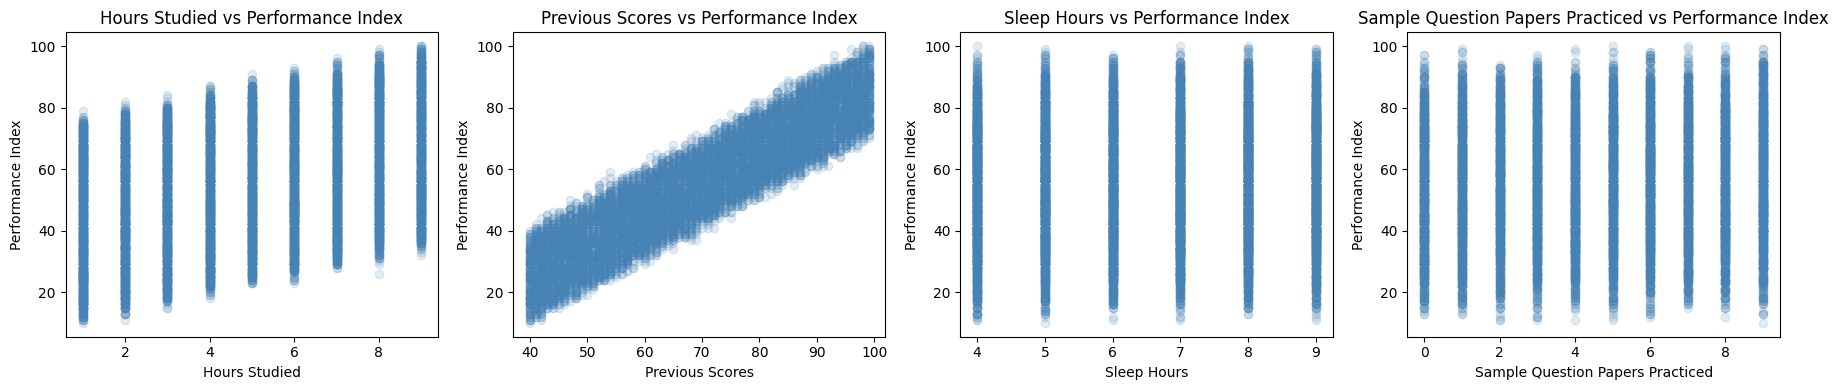

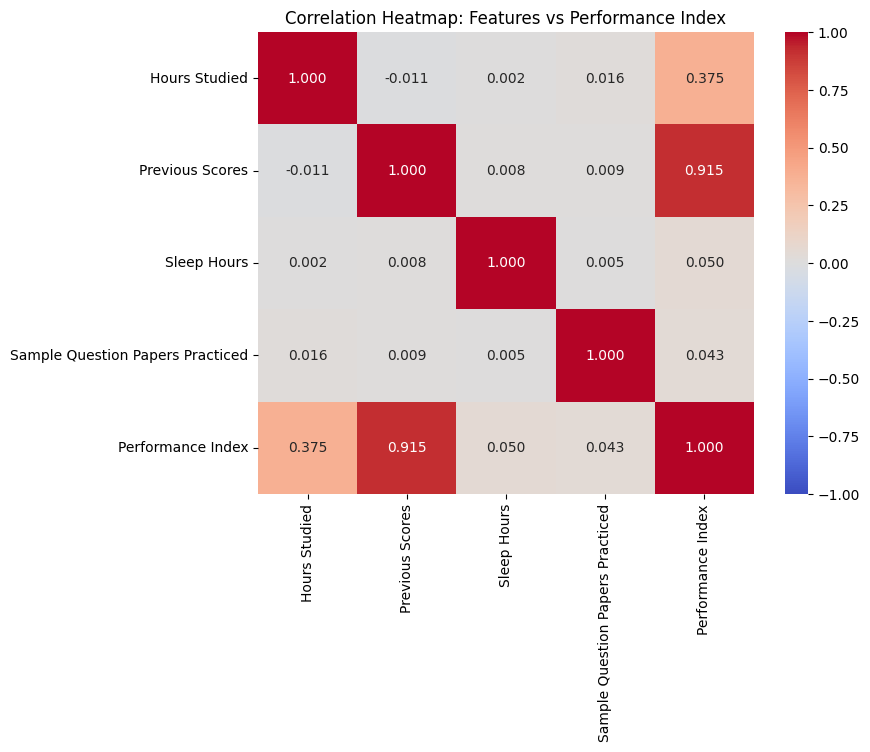

In [5]:
# CELL 3: Step 3 - Visualise Relationships & Correlation Matrix
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(features):
    axes[i].scatter(X_full[col], y_full, alpha=0.15, color='steelblue')
    axes[i].set_title(f'{col} vs {target}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target)
plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6))
corr_matrix = df_clean[features + [target]].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap: Features vs Performance Index')
plt.show()

In [6]:
# CELL 4: Step 4 Verification & Step 5 Train/Test Split + Modeling
# 1. Verify Manual Calculation on the exact 6-row sample
X_sample = df[['Hours Studied', 'Previous Scores']].iloc[:6]
y_sample = df['Performance Index'].iloc[:6]

sample_model = LinearRegression()
sample_model.fit(X_sample, y_sample)
print("--- Manual Calculation Verification (First 6 Rows) ---")
print(f"Library Intercept (b0): {sample_model.intercept_:.4f} (Manual: -29.1398)")
print(f"Library Coeffs (b1, b2): {sample_model.coef_[0]:.4f}, {sample_model.coef_[1]:.4f} (Manual: 2.5197, 1.0370)\n")

# 2. 80:20 Train-Test Split on Clean Full Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.20, random_state=RANDOM_SEED
)
print(f"Training Set Size: {X_train.shape[0]} rows | Testing Set Size: {X_test.shape[0]} rows\n")

# 3. Single-Feature Baseline Model (Most correlated feature: Previous Scores)
best_single_feature = ['Previous Scores']
single_model = LinearRegression()
single_model.fit(X_train[best_single_feature], y_train)
y_pred_single = single_model.predict(X_test[best_single_feature])

print("--- Single-Feature Baseline Model ---")
print(f"Intercept: {single_model.intercept_:.4f}")
print(f"Coefficient (Previous Scores): {single_model.coef_[0]:.4f}")
print(f"Test R2: {r2_score(y_test, y_pred_single):.4f}\n")

# 4. Multiple Linear Regression Model (All 4 Numerical Features)
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)

print("--- Multiple Linear Regression Model ---")
print(f"Intercept: {multi_model.intercept_:.4f}")
for feat, coef in zip(features, multi_model.coef_):
    print(f"Coefficient ({feat}): {coef:.4f}")

# 5. Standardised Coefficients (Fit scaler on training data ONLY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
multi_model_scaled = LinearRegression().fit(X_train_scaled, y_train)

print("\n--- Standardised Coefficients (Relative Importance) ---")
for feat, scoef in zip(features, multi_model_scaled.coef_):
    print(f"Standardised Coef ({feat}): {scoef:.4f}")

--- Manual Calculation Verification (First 6 Rows) ---
Library Intercept (b0): -29.1364 (Manual: -29.1398)
Library Coeffs (b1, b2): 2.5197, 1.0370 (Manual: 2.5197, 1.0370)

Training Set Size: 7898 rows | Testing Set Size: 1975 rows

--- Single-Feature Baseline Model ---
Intercept: -15.2740
Coefficient (Previous Scores): 1.0150
Test R2: 0.8358

--- Multiple Linear Regression Model ---
Intercept: -33.6875
Coefficient (Hours Studied): 2.8514
Coefficient (Previous Scores): 1.0186
Coefficient (Sleep Hours): 0.4678
Coefficient (Sample Question Papers Practiced): 0.1904

--- Standardised Coefficients (Relative Importance) ---
Standardised Coef (Hours Studied): 7.3744
Standardised Coef (Previous Scores): 17.6222
Standardised Coef (Sleep Hours): 0.7949
Standardised Coef (Sample Question Papers Practiced): 0.5450


In [7]:
# CELL 5: Steps 7 & 8 - Predictions & Evaluation Metrics Table
comparison_df = pd.DataFrame({
    'Actual Performance Index': y_test.values[:10],
    'Predicted (Multiple MLR)': np.round(y_pred_multi[:10], 2),
    'Residual (Actual - Pred)': np.round(y_test.values[:10] - y_pred_multi[:10], 2)
})
display(comparison_df)

def evaluate_regression(y_true, y_pred, n_features):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - n_features - 1))
    return [mae, mse, rmse, r2, adj_r2]

metrics_table = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²', 'Adjusted R²'],
    'Single-Feature Model (Previous Scores)': evaluate_regression(y_test, y_pred_single, 1),
    'Multiple-Feature Model (All 4 Features)': evaluate_regression(y_test, y_pred_multi, len(features))
})
display(metrics_table.round(4))

,Actual Performance Index,Predicted (Multiple MLR),Residual (Actual - Pred)
0,47.0,46.20,0.80
1,76.0,80.00,-4.00
2,62.0,60.77,1.23
3,23.0,23.00,0.00
4,76.0,75.12,0.88
5,83.0,83.90,-0.90
6,60.0,61.71,-1.71
7,51.0,50.04,0.96
8,38.0,38.62,-0.62
9,58.0,55.46,2.54


,Metric,Single-Feature Model (Previous Scores),Multiple-Feature Model (All 4 Features)
0,MAE,6.7087,1.6762
1,MSE,61.1107,4.4493
2,RMSE,7.8173,2.1093
3,R²,0.8358,0.9880
4,Adjusted R²,0.8357,0.9880


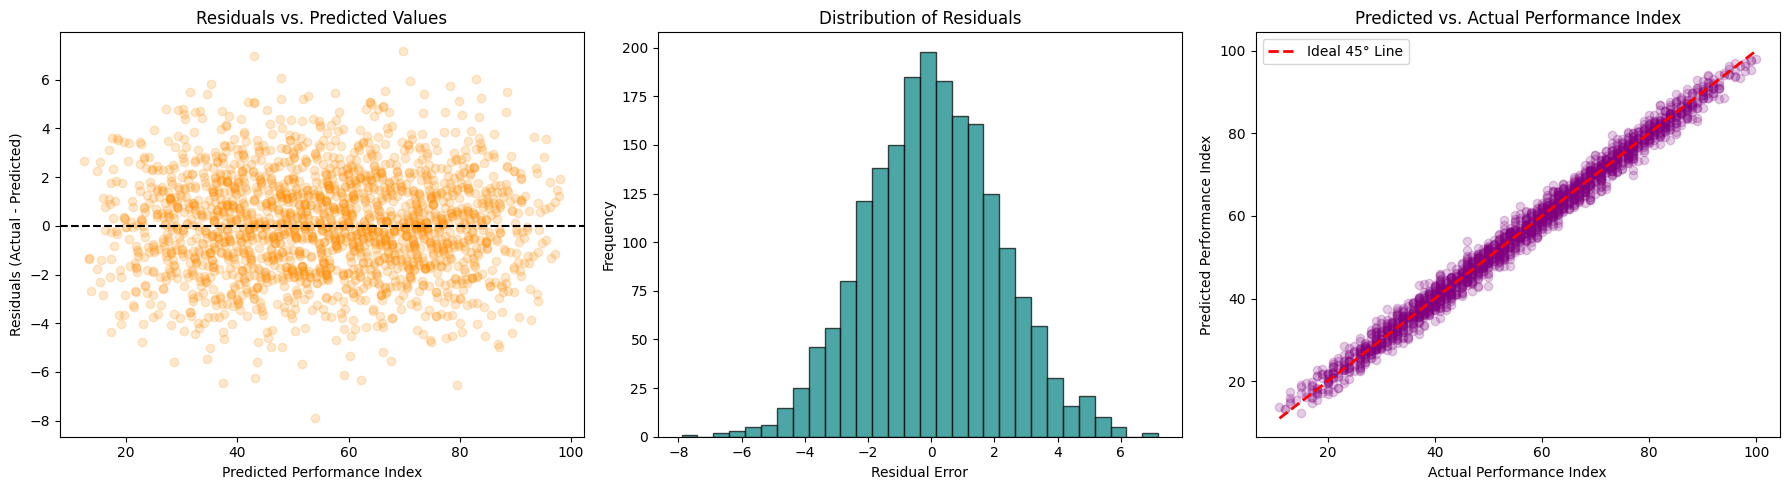


--- Variance Inflation Factor (VIF) ---


,Feature,VIF
0,Hours Studied,1.0005
1,Previous Scores,1.0002
2,Sleep Hours,1.0001
3,Sample Question Papers Practiced,1.0005


In [8]:
# CELL 6: Step 9 - Residual Analysis & Multicollinearity (VIF)
residuals = y_test - y_pred_multi

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs Predicted
axes[0].scatter(y_pred_multi, residuals, alpha=0.2, color='darkorange')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('Residuals vs. Predicted Values')
axes[0].set_xlabel('Predicted Performance Index')
axes[0].set_ylabel('Residuals (Actual - Predicted)')

# 2. Histogram of Residuals
axes[1].hist(residuals, bins=30, color='teal', edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Frequency')

# 3. Predicted vs Actual with 45-degree line
axes[2].scatter(y_test, y_pred_multi, alpha=0.2, color='purple')
min_val, max_val = y_test.min(), y_test.max()
axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal 45° Line')
axes[2].set_title('Predicted vs. Actual Performance Index')
axes[2].set_xlabel('Actual Performance Index')
axes[2].set_ylabel('Predicted Performance Index')
axes[2].legend()

plt.tight_layout()
plt.show()

# VIF Calculation for Multicollinearity
vif_data = pd.DataFrame()
vif_data['Feature'] = features
vif_data['VIF'] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
print("\n--- Variance Inflation Factor (VIF) ---")
display(vif_data.round(4))

In [9]:
# CELL 7: Step 10 - Predict a New Student Example
new_student = pd.DataFrame({
    'Hours Studied': [6],
    'Previous Scores': [80],
    'Sleep Hours': [7],
    'Sample Question Papers Practiced': [5]
})

predicted_score = multi_model.predict(new_student)[0]
print(f"New Student Input:\n{new_student.to_string(index=False)}")
print(f"\nPredicted Performance Index: {predicted_score:.2f} / 100")

New Student Input:
 Hours Studied  Previous Scores  Sleep Hours  Sample Question Papers Practiced
             6               80            7                                 5

Predicted Performance Index: 69.13 / 100
